# Roll control analysis, part two
Onboard files only (**no TeleMega data**). One figure per file, all against `relseconds`:

| Figure | File | Plotted |
|---|---|---|
| 1 | GPS.csv | altitude and change in altitude |
| 2 | Controls Feedback.csv (orientation) | pitch and yaw |
| 3 | Primary Gyroscope.csv | y and z |
| 4 | Accelerometer.csv | z only |

**How to read the graphs.** The onboard log repeats the previous row whenever no new data arrived, so only *fresh* rows (any value changed from the row before) are drawn, each as one dot. Consecutive dots are joined by straight line segments (connect-the-dots, no fitting or smoothing). A long straight segment therefore means a gap in the data, not a measured trend.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

D = '/Users/jason/Downloads/'
P = '19-06-2026-00-44-18-'
OUT = D + 'roll_control_analysis/'          # PNG copies of each figure are saved here
T0, T1 = 100, 127.5                         # flight window shown (onboard relseconds)

gps  = pd.read_csv(D + P + '0xC0-0-GPS.csv')
ori  = pd.read_csv(D + P + '0xC1-0-Controls Feedback.csv')      # orientation quaternion (w, x, y, z)
gyro = pd.read_csv(D + P + '0xB1-0-Primary Gyroscope.csv')
acc  = pd.read_csv(D + P + '0xB0-0-Accelerometer.csv')

def fresh_rows(df, cols):
    """Rows inside the flight window where at least one of `cols` changed from the previous row."""
    changed = df[cols].diff().abs().sum(axis=1) > 0
    return df[changed & (df.relseconds >= T0) & (df.relseconds <= T1)].reset_index(drop=True)

def format_time_axis(ax):
    ax.set_xlim(T0 - 0.2, T1 + 0.2)
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_minor_locator(MultipleLocator(0.5))
    ax.tick_params(axis='x', labelsize=8, labelrotation=60)
    ax.set_xlabel('relseconds (s)')
    ax.grid(alpha=0.3)
    ax.grid(which='minor', axis='x', alpha=0.12)

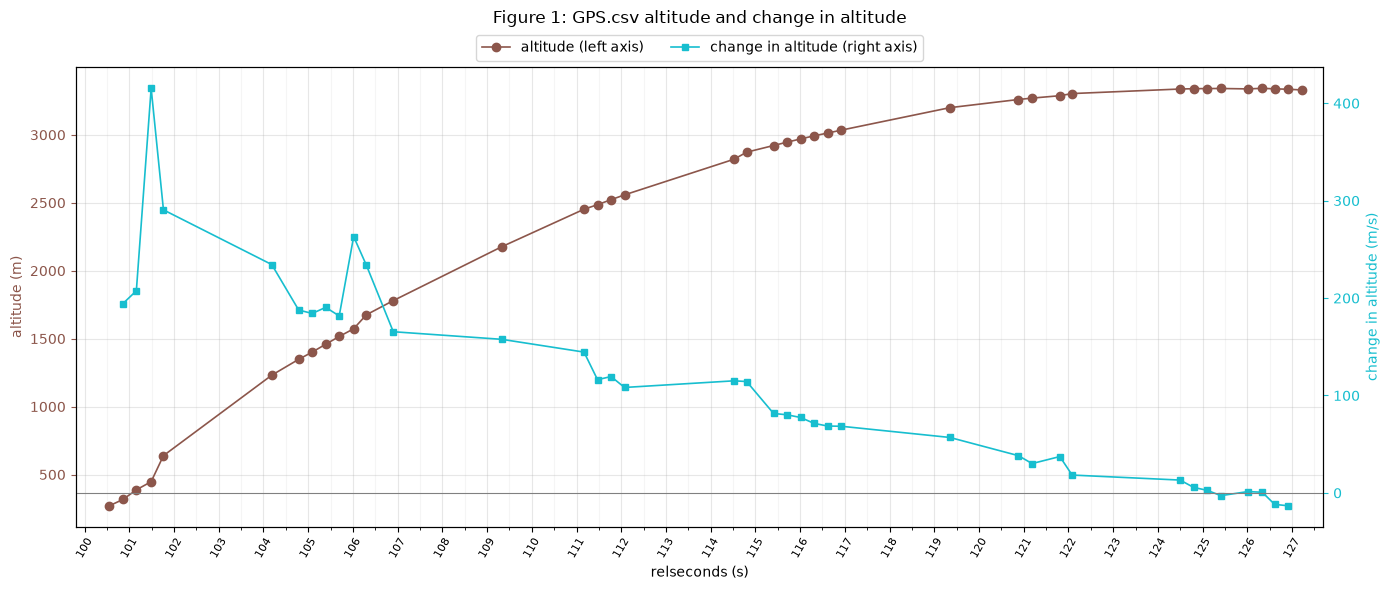

In [2]:
# ---- Figure 1: GPS.csv -- altitude and change in altitude -----------------------------------------------
g = fresh_rows(gps, ['altitude'])
t, h = g.relseconds.to_numpy(), g.altitude.to_numpy()
# change in altitude = centered difference between the neighbouring fresh samples (m/s), drawn at the middle sample
t_v = t[1:-1]
v = (h[2:] - h[:-2]) / (t[2:] - t[:-2])

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(t, h, 'o-', lw=1.2, color='tab:brown', ms=6, label='altitude (left axis)')
ax.set_ylabel('altitude (m)', color='tab:brown'); ax.tick_params(axis='y', colors='tab:brown')
ax2 = ax.twinx()
ax2.plot(t_v, v, 's-', lw=1.2, color='tab:cyan', ms=5, label='change in altitude (right axis)')
ax2.axhline(0, color='gray', lw=0.8)
ax2.set_ylabel('change in altitude (m/s)', color='tab:cyan'); ax2.tick_params(axis='y', colors='tab:cyan')
format_time_axis(ax)
ax.set_title('Figure 1: GPS.csv altitude and change in altitude', pad=32)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.tight_layout(); plt.savefig(OUT + 'two_fig1_gps_altitude.png', dpi=150); plt.show()

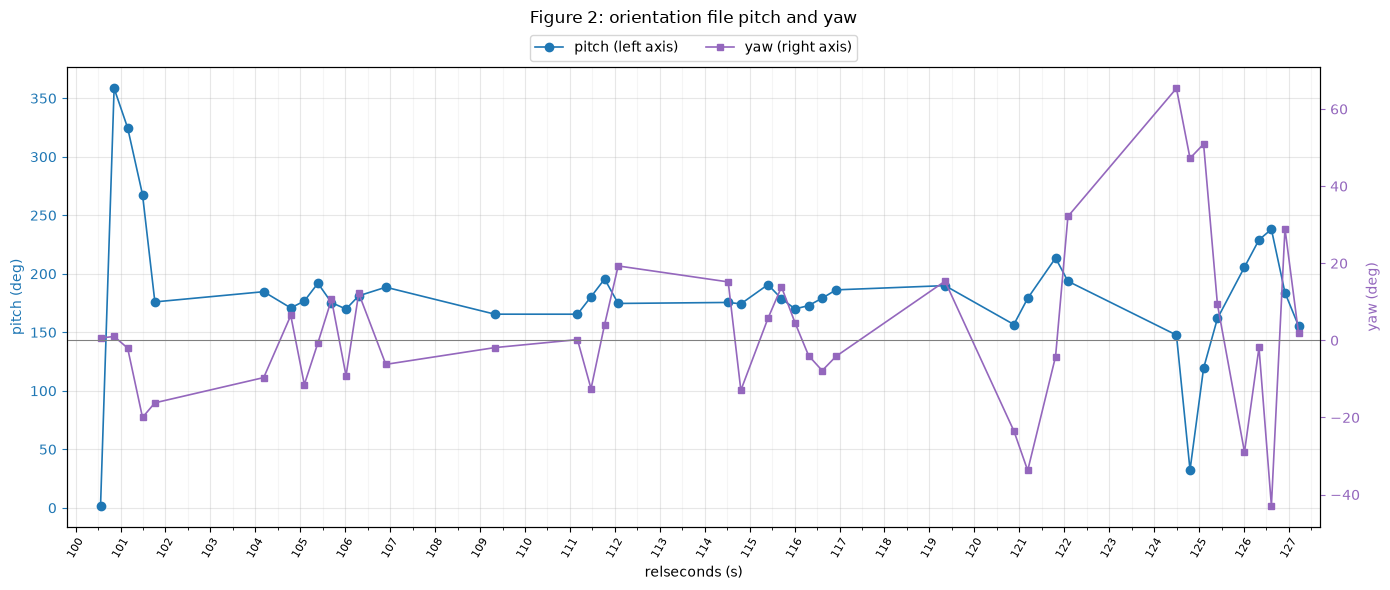

In [3]:
# ---- Figure 2: orientation (Controls Feedback.csv) -- pitch and yaw -------------------------------------
# The file stores a unit quaternion (w, x, y, z). The rocket's long (roll) axis is the body z axis, so the
# Euler angles are taken in intrinsic X-Y-Z order: rotation about x = pitch, about y = yaw, and the roll
# about z comes last, so it does not leak into pitch or yaw.
o = fresh_rows(ori, ['w', 'x', 'y', 'z'])
q = o[['w', 'x', 'y', 'z']].to_numpy(); q = q / np.linalg.norm(q, axis=1)[:, None]
w, x, y, z = q.T
R02 = 2 * (x * z + y * w)
R12 = 2 * (y * z - x * w)
R22 = 1 - 2 * (x * x + y * y)
yaw   = np.degrees(np.arcsin(np.clip(R02, -1, 1)))      # about y
pitch = np.degrees(np.arctan2(-R12, R22)) % 360         # about x, shown 0-360 so the ~180 deg cluster stays continuous

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(o.relseconds, pitch, 'o-', lw=1.2, color='tab:blue', ms=6, label='pitch (left axis)')
ax.set_ylabel('pitch (deg)', color='tab:blue'); ax.tick_params(axis='y', colors='tab:blue')
ax2 = ax.twinx()
ax2.plot(o.relseconds, yaw, 's-', lw=1.2, color='tab:purple', ms=5, label='yaw (right axis)')
ax2.axhline(0, color='gray', lw=0.8)
ax2.set_ylabel('yaw (deg)', color='tab:purple'); ax2.tick_params(axis='y', colors='tab:purple')
format_time_axis(ax)
ax.set_title('Figure 2: orientation file pitch and yaw', pad=32)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.tight_layout(); plt.savefig(OUT + 'two_fig2_orientation_pitch_yaw.png', dpi=150); plt.show()

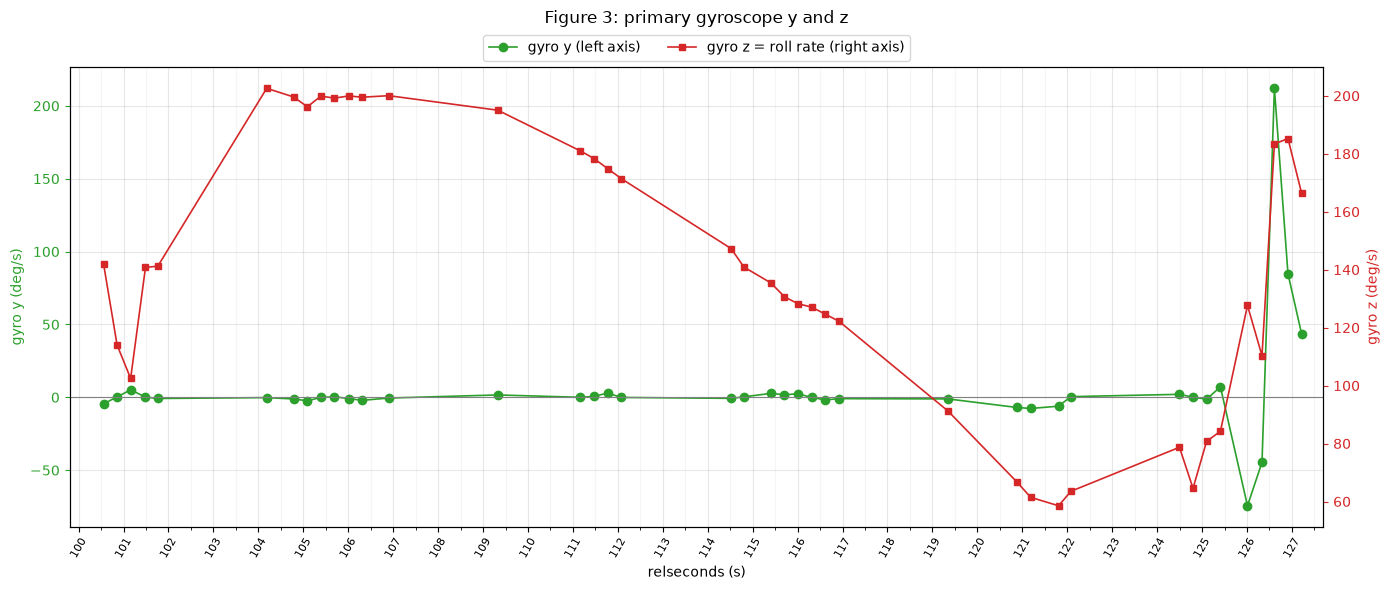

In [4]:
# ---- Figure 3: Primary Gyroscope.csv -- y and z ----------------------------------------------------------
gy = fresh_rows(gyro, ['x', 'y', 'z'])

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(gy.relseconds, gy.y, 'o-', lw=1.2, color='tab:green', ms=6, label='gyro y (left axis)')
ax.axhline(0, color='gray', lw=0.8)
ax.set_ylabel('gyro y (deg/s)', color='tab:green'); ax.tick_params(axis='y', colors='tab:green')
ax2 = ax.twinx()
ax2.plot(gy.relseconds, gy.z, 's-', lw=1.2, color='tab:red', ms=5, label='gyro z = roll rate (right axis)')
ax2.set_ylabel('gyro z (deg/s)', color='tab:red'); ax2.tick_params(axis='y', colors='tab:red')
format_time_axis(ax)
ax.set_title('Figure 3: primary gyroscope y and z', pad=32)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.tight_layout(); plt.savefig(OUT + 'two_fig3_gyro_y_z.png', dpi=150); plt.show()

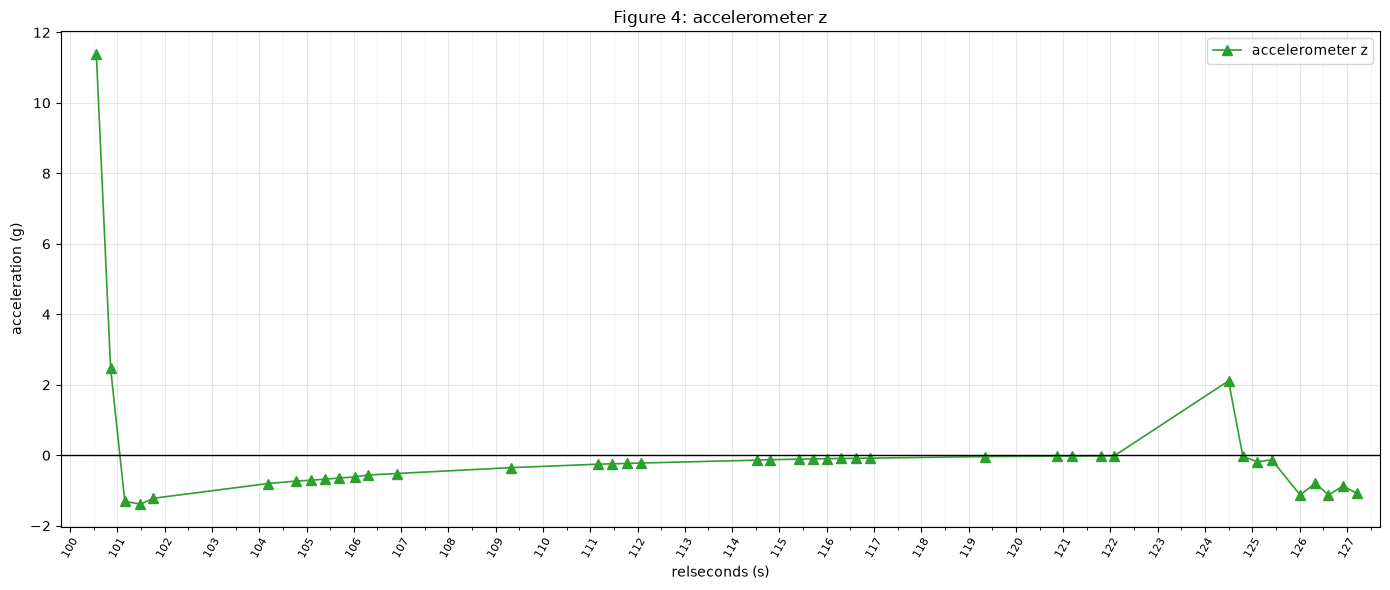

In [5]:
# ---- Figure 4: Accelerometer.csv -- z only ---------------------------------------------------------------
az = fresh_rows(acc, ['x', 'y', 'z'])

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(az.relseconds, az.z, '^-', lw=1.2, color='tab:green', ms=7, label='accelerometer z')
ax.axhline(0, color='k', lw=1)
ax.set_ylabel('acceleration (g)')
format_time_axis(ax)
ax.set_title('Figure 4: accelerometer z')
ax.legend(loc='upper right')
plt.tight_layout(); plt.savefig(OUT + 'two_fig4_accelerometer_z.png', dpi=150); plt.show()